# Лабораторная работа № 6. Механизм attention и Transformer encoder

**Тема:** self-attention, multi-head attention, позиционные представления и архитектура Transformer encoder.

**Цель:** понять, как механизм внимания связывает токены внутри последовательности, самостоятельно реализовать базовые операции attention и собрать классификатор текста на основе Transformer encoder.

В предыдущей работе мы рассматривали рекуррентные сети. Теперь познакомимся с другим способом построения контекстных представлений: каждый токен сможет напрямую учитывать информацию из других позиций последовательности. Сначала разберём механизм внимания и устройство Encoder, а затем применим полученные знания к задаче классификации текста.

In [ ]:
# Проверяем версии библиотек и выбираем устройство, на котором будут выполняться вычисления.
import sys
import platform
import torch

# Сначала фиксируем версии среды: это помогает понять, какие возможности PyTorch и CUDA доступны.
print(f"Python: {sys.version.split()[0]}")
print(f"Платформа: {platform.platform()}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA доступна: {torch.cuda.is_available()}")
print(f"CUDA-сборка PyTorch: {torch.version.cuda}")

# Выбираем единое устройство для дальнейших вычислений; при отсутствии CUDA используем CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство для вычислений: {device}")

# Дополнительные сведения о видеокарте выводим только тогда, когда CUDA действительно доступна.
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"CUDA-устройств: {torch.cuda.device_count()}")

## Что было рассмотрено в лабораторной работе № 5

В прошлой работе мы сравнивали усреднение embedding, RNN, LSTM и GRU. Рекуррентные сети последовательно обновляют скрытое состояние: чтобы обработать очередной токен, им требуется состояние предыдущего шага.

У такого подхода есть ограничения:

- вычисления по временным шагам зависят друг от друга, поэтому последовательность сложно обрабатывать параллельно;
- информация о ранних токенах должна пройти через цепочку рекуррентных обновлений;
- обучение длинных последовательностей может осложняться затуханием и взрывом градиентов.

Механизм внимания предлагает другой способ построения контекста: при обработке каждого токена модель может напрямую обратиться к другим токенам последовательности. Для self-attention все позиции одного текста обрабатываются совместно, без рекуррентного перехода от шага к шагу.

## Архитектура Transformer и роль Encoder

Архитектура Transformer была предложена в статье **Attention Is All You Need** для задачи машинного перевода. Вместо рекуррентной обработки в ней используется механизм внимания, а информацию о порядке элементов добавляют позиционные представления.

В исходной архитектуре две крупные части:

- **Encoder** получает входную последовательность и преобразует её в контекстные представления токенов.
- **Decoder** использует представления Encoder и формирует выходную последовательность.

В этой работе рассматриваем только **Transformer Encoder**. Он подходит для задач, в которых вся входная последовательность доступна сразу: например, для классификации текста. Decoder и авторегрессионную генерацию текста мы рассмотрим в следующей работе.

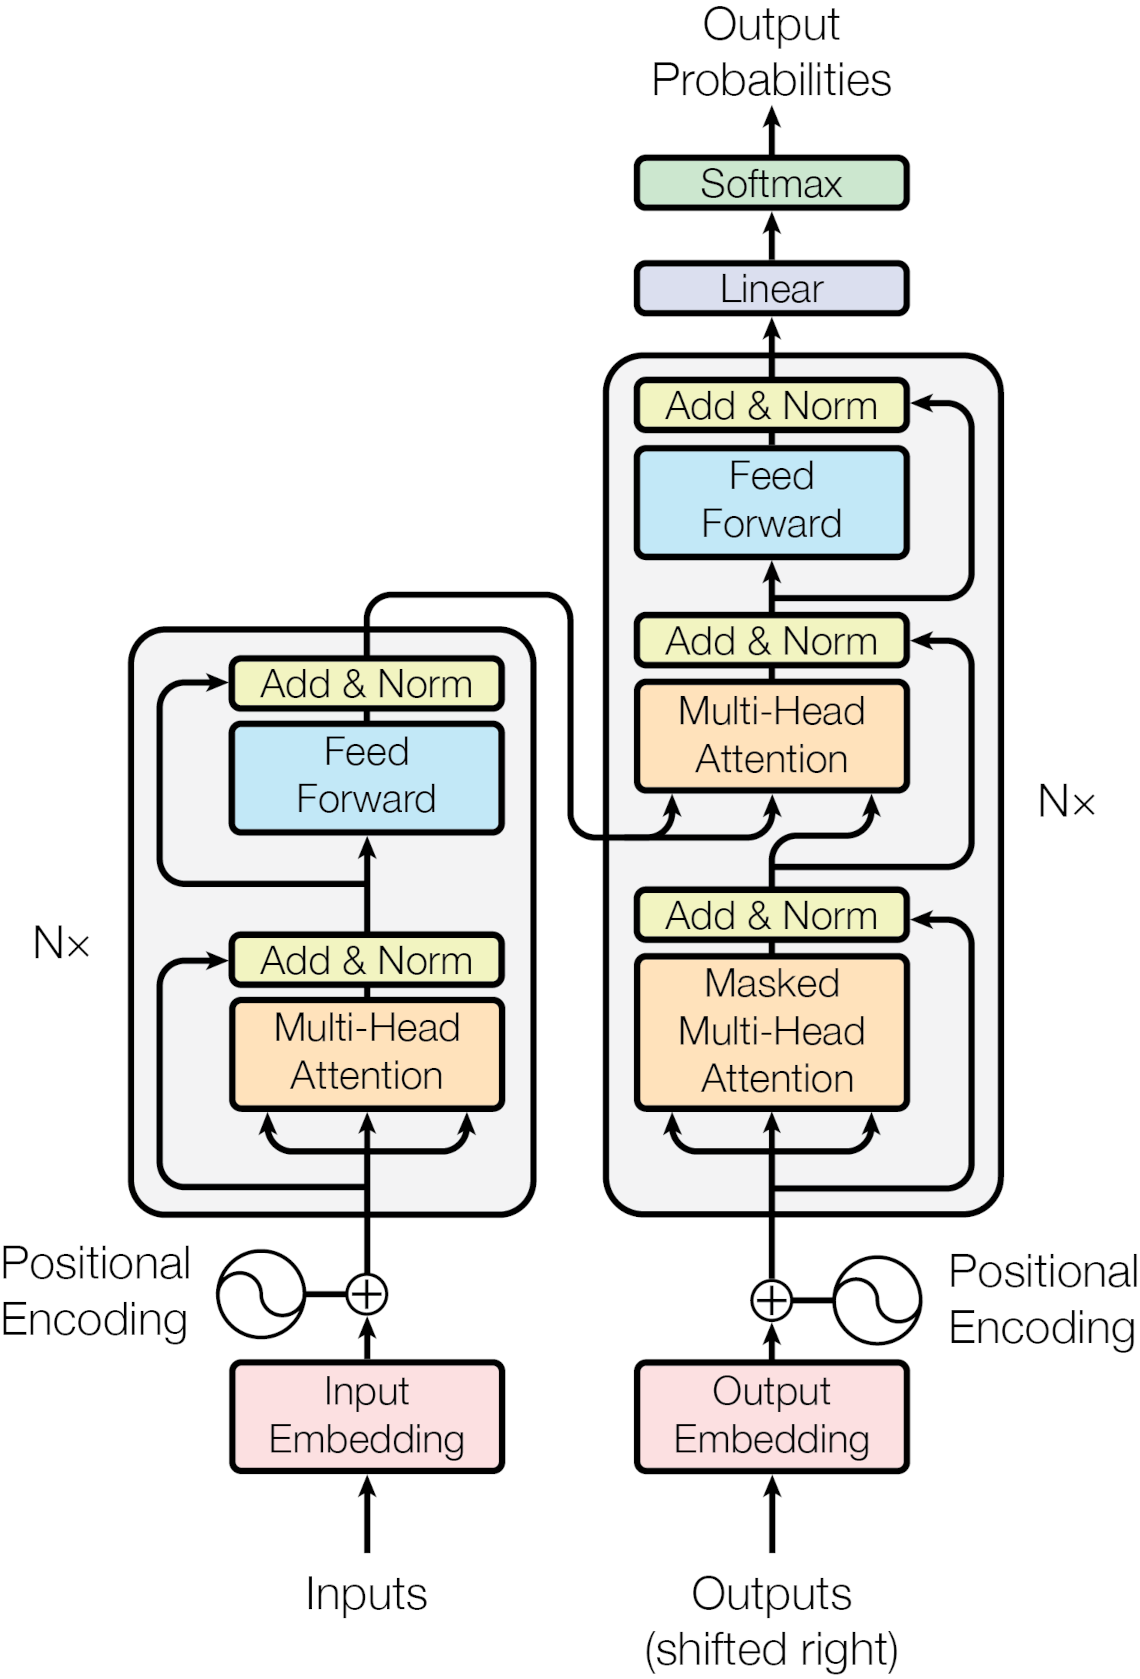

## Идея механизма self-attention

Представим, что мы читаем новость и пытаемся определить её тематику. Чтобы понять значение слова, часто полезно посмотреть на другие слова: `coach` рядом со словами `team`, `match` и `league` скорее указывает на спортивный контекст, чем на бизнес.

Self-attention позволяет каждой позиции последовательности выбрать, от каких других позиций получить информацию. При этом все токены одного текста обрабатываются совместно: нет рекуррентного перехода от предыдущего шага к следующему.

Для этого каждому входному вектору строятся три представления: **Query**, **Key** и **Value**. Их удобно сравнить с поиском информации: Query - что текущая позиция хочет найти, Key - по каким признакам можно сопоставить позицию с запросом, Value - какая информация будет передана, если позиция получит высокий вес внимания.

### Query, Key и Value

Пусть входные векторы последовательности собраны в тензор $X$ формы `[B, T, E]`, где $B$ - размер батча, $T$ - длина последовательности, $E$ - размерность embedding.

Для одной головы внимания вычисляются три линейные проекции:

$$
Q=XW_Q,\qquad K=XW_K,\qquad V=XW_V.
$$

Матрицы $W_Q$, $W_K$ и $W_V$ - обучаемые параметры. Это не три вида токенов и не заранее заданные семантические признаки: все три представления строятся из одного и того же входа и настраиваются в процессе обучения.

Для каждой Query-позиции вычисляется степень соответствия Key-векторам других позиций. Чем выше оценка, тем больший вес получит соответствующий Value при формировании нового представления.

### Scaled dot-product attention

Сначала вычисляются скалярные произведения Query и Key:

$$
S=QK^T.
$$

После масштабирования, softmax и взвешенного суммирования Value получается результат внимания:

$$
\operatorname{Attention}(Q,K,V)=
\operatorname{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V,
$$

где $d_k$ - размерность Query и Key.

**Зачем делить оценки на $\sqrt{d_k}$?** При увеличении размерности скалярные произведения обычно становятся больше по абсолютному значению. Softmax может начать выдавать слишком резкое распределение: отдельные позиции получают почти всю вероятность, остальные - почти нулевую. Масштабирование помогает удерживать значения в удобном диапазоне и сохранять полезные градиенты.

Матрица весов внимания для одного текста имеет форму `[T, T]`. Строка соответствует Query-позиции, столбец - Key-позиции. После softmax сумма весов в каждой строке равна единице.

<video controls style="width: stretch; max-width: 1280px;" src="..."></video>

### Маскирование padding

В батче тексты имеют разную длину, поэтому короткие последовательности дополняются токеном `<PAD>`. Эти позиции не должны становиться источниками информации. Перед softmax соответствующие оценки внимания заменяются на $-\infty$, и после softmax их веса становятся нулевыми.

Маска ключей имеет форму `[B, T]`: значение `True` означает, что позиция является padding. В дальнейшем такая маска будет передаваться и в ручную реализацию attention, и в `nn.TransformerEncoder`.

In [2]:
# Строим булеву маску, где True обозначает padding-позиции.
def pad_mask_from_lengths(lengths: torch.Tensor) -> torch.Tensor:
    max_len = int(lengths.max().item())

    # Заполним все позиции индексом токена.
    positions = torch.arange(max_len, device=lengths.device).unsqueeze(0)

    # Если индекс >= lengths, значит этот токен - padding.
    return positions >= lengths.unsqueeze(1)  # (batch_size, max_len).

In [3]:
# Проверяем построение padding mask на последовательностях разной длины.
mask_lengths = torch.tensor([5, 3, 1], device=device)
example_pad_mask = pad_mask_from_lengths(mask_lengths)

print(example_pad_mask.int())

tensor([[0, 0, 0, 0, 0],
        [0, 0, 0, 1, 1],
        [0, 1, 1, 1, 1]], device='cuda:0', dtype=torch.int32)


### Реализация scaled dot-product attention

Для удобства будем поддерживать входные тензоры `[B, T, D]`, а также `[B, H, T, D]`: второй формат понадобится при реализации нескольких голов.

Функция должна возвращать контекст формы, совпадающей с формой `query`, и веса внимания. Для обычной головы их форма - `[B, T, T]`, для нескольких голов - `[B, H, T, T]`.

Проверьте, что веса каждой строки суммируются в единицу, а позиции padding получают нулевой вес.

In [ ]:
# Реализуйте scaled dot-product attention.
import math
import torch.nn as nn
import torch.nn.functional as F


def scaled_dot_product_attention(
    query: torch.Tensor,
    key: torch.Tensor,
    value: torch.Tensor,
    key_padding_mask: torch.Tensor | None = None,
) -> tuple[torch.Tensor, torch.Tensor]:
    # Вычислите QK^T и разделите оценки на sqrt(d_k).
    d_k = query.size(-1)

    # Транспонируйте K с помощью key.transpose(-2, -1).
    scores = ...

    # Маскируем padding-позиции.
    if key_padding_mask is not None:
        mask = key_padding_mask

        while mask.dim() < scores.dim():
            mask = mask.unsqueeze(1)

        scores = scores.masked_fill(mask, float("-inf"))

    # Примените softmax по последнему измерению.
    attention_weights = ...

    # Вычисляем взвешенную сумму Value.
    output = ...

    return output, attention_weights

In [5]:
# Проверяем реализацию attention на небольших тензорах с разными длинами.
generator = torch.Generator(device=device).manual_seed(42)
demo_batch_size = 2
demo_seq_len = 6
demo_dim = 16
demo_lengths = torch.tensor([6, 4], device=device)
demo_pad_mask = pad_mask_from_lengths(demo_lengths)

query = torch.randn(
    demo_batch_size, demo_seq_len, demo_dim, device=device, generator=generator
)
key = torch.randn(
    demo_batch_size, demo_seq_len, demo_dim, device=device, generator=generator
)
value = torch.randn(
    demo_batch_size, demo_seq_len, demo_dim, device=device, generator=generator
)

context, attention_weights = scaled_dot_product_attention(
    query, key, value, key_padding_mask=demo_pad_mask
)

assert torch.allclose(
    attention_weights.sum(dim=-1),
    torch.ones(demo_batch_size, demo_seq_len, device=device),
    atol=1e-5,
)
assert torch.allclose(
    attention_weights[1, :, 4:],
    torch.zeros_like(attention_weights[1, :, 4:]),
    atol=1e-6,
)

print("Context:", tuple(context.shape))
print("Attention weights:", tuple(attention_weights.shape))
print("Сумма весов в строке:", attention_weights[0, 0].sum().item())
print("Максимальный вес на PAD:", attention_weights[1, :, 4:].max().item())

Context: (2, 6, 16)
Attention weights: (2, 6, 6)
Сумма весов в строке: 1.0
Максимальный вес на PAD: 0.0


## Multi-head attention

Одна голова внимания строит один вариант контекстного представления. Но отношения между токенами могут быть разными. Одна голова может сильнее учитывать близкие слова, другая - названия организаций, третья - связь между субъектом и действием.

Multi-head attention запускает несколько механизмов внимания с разными обучаемыми проекциями. Каждая голова работает со своей частью признакового пространства, после чего результаты объединяются.

### Несколько голов и выходная проекция

Пусть размерность входного embedding равна $E$, а число голов - $H$. Размерность одной головы равна $D=E/H$. Для каждой головы строятся собственные проекции:

$$
Q_i=XW_Q^{(i)},\qquad K_i=XW_K^{(i)},\qquad V_i=XW_V^{(i)}.
$$

Головы независимо вычисляют attention. Их результаты конкатенируются вдоль признакового измерения:

$$
\operatorname{Concat}(head_1,\ldots,head_H)\in\mathbb{R}^{B\times T\times E}.
$$

После конкатенации применяется дополнительный обучаемый линейный слой $W_O$. Он смешивает признаки, пришедшие от разных голов, и формирует общий выход multi-head attention.

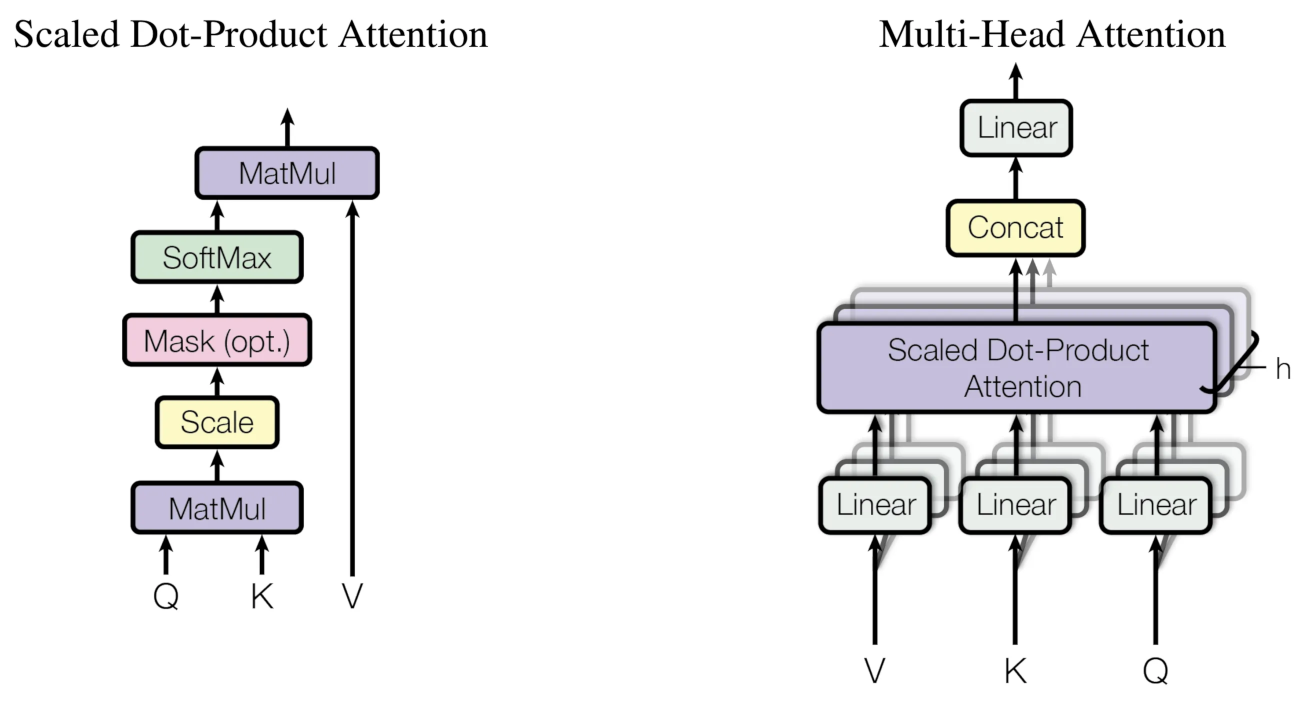

### Объединение проекций Q, K и V

Наивная реализация выполняет три линейных преобразования на каждую голову отдельно. Но $Q_i$, $K_i$ и $V_i$ строятся из одного входного тензора, поэтому матрицы весов можно объединить в одну большую матрицу:

$$
W_{QKV}=[W_Q\;W_K\;W_V],\qquad [Q,K,V]=XW_{QKV}.
$$

В PyTorch это обычно реализуется одним `nn.Linear(E, 3*E)`, после которого результат разделяется на $Q$, $K$ и $V$. Дальше каждая из полученных матриц $Q$, $K$ и $V$ разделяется на $H$ равных частей. Вместо $3H$ небольших матричных умножений получается одна более крупная операция. Это уменьшает накладные расходы на запуск вычислений и часто лучше использует GPU.

### Реализация MultiHeadSelfAttention

Используем один `Linear(E, 3*E)` для совместного вычисления Q, K и V. Затем разделите размерность embedding на `num_heads` частей и выполните attention для каждой головы.

Ожидаемые формы:

- вход: `[B, T, E]`;
- Q, K, V после разбиения: `[B, H, T, D]`;
- веса внимания: `[B, H, T, T]`;
- контекст после объединения голов: `[B, T, E]`;
- выходная проекция: `[B, T, E]`.

Проверьте, что `embedding_dim` делится на `num_heads`. Внутри `forward` используйте написанную выше функцию `scaled_dot_product_attention`.

In [ ]:
# Реализуйте multi-head self-attention с объединённой проекцией QKV.
from typing import TypeAlias

TensorPair: TypeAlias = tuple[torch.Tensor, torch.Tensor]


class MultiHeadSelfAttention(nn.Module):
    def __init__(self, embedding_dim: int, num_heads: int) -> None:
        super().__init__()
        assert embedding_dim % num_heads == 0

        self.embedding_dim = embedding_dim
        self.num_heads = num_heads
        self.head_dim = embedding_dim // num_heads

        self.qkv = nn.Linear(embedding_dim, 3 * embedding_dim)
        self.out_proj = nn.Linear(embedding_dim, embedding_dim)

    def forward(
        self,
        x: torch.Tensor,
        key_padding_mask: torch.Tensor | None = None,
    ) -> TensorPair:
        batch_size, seq_len, _ = x.shape

        # Одним Linear вычисляем Q, K и V.
        qkv = ...

        # [B, T, 3*E] -> [B, T, 3, H, D].
        qkv = qkv.reshape(batch_size, seq_len, 3, self.num_heads, self.head_dim)

        # [B, T, 3, H, D] -> [3, B, H, T, D].
        qkv = qkv.permute(2, 0, 3, 1, 4)

        # Разделяем Q, K, V.
        query, key, value = qkv.unbind(0)

        # Примените scaled_dot_product_attention к каждой голове.
        attention_output, attention_weights = ...

        # [B, H, T, D] -> [B, T, H, D] -> [B, T, E].
        attention_output = attention_output.transpose(1, 2).contiguous()
        attention_output = attention_output.reshape(
            batch_size, seq_len, self.embedding_dim
        )

        # Финальная проекция.
        output = ...

        return output, attention_weights

In [7]:
# Проверяем формы, нормировку весов и исключение padding в multi-head attention.

demo_mha = MultiHeadSelfAttention(embedding_dim=32, num_heads=4).to(device)
mha_input = torch.randn(2, 7, 32, device=device, generator=generator)
mha_lengths = torch.tensor([7, 5], device=device)
mha_mask = pad_mask_from_lengths(mha_lengths)

mha_output, mha_weights = demo_mha(mha_input, key_padding_mask=mha_mask)

assert mha_output.shape == (2, 7, 32)
assert mha_weights.shape == (2, 4, 7, 7)
assert torch.allclose(
    mha_weights.sum(dim=-1), torch.ones(2, 4, 7, device=device), atol=1e-5
)
assert torch.allclose(
    mha_weights[1, :, :, 5:],
    torch.zeros_like(mha_weights[1, :, :, 5:]),
    atol=1e-6,
)

print("Multi-head output:", tuple(mha_output.shape))
print("Attention weights:", tuple(mha_weights.shape))

Multi-head output: (2, 7, 32)
Attention weights: (2, 4, 7, 7)


## Позиционная информация

Self-attention сам по себе не задаёт порядок токенов. Если переставить токены вместе с их embedding, вычисления внимания будут соответствовать той же перестановке: механизм не узнает, что исходный порядок изменился.

Для текста это ограничение принципиально. Поэтому к embedding каждого токена добавляется позиционное представление. Можно использовать обучаемую таблицу позиционных векторов. Здесь рассмотрим фиксированное синусоидальное кодирование из исходной архитектуры Transformer.

### Синусоидальное позиционное кодирование

Для его вычисления используются две величины:

- `pos` - порядковый номер токена в последовательности, начиная с нуля.
- `i` - номер пары координат внутри вектора позиционного кодирования. Каждая пара состоит из двух соседних координат: `2i` и `2i+1`.

Для каждой позиции `pos` вычисляется вектор размерности `E`. Его координаты заполняются синусом и косинусом:

$$
PE(pos,2i)=\sin\left(\frac{pos}{10000^{2i/E}}\right),
$$

$$
PE(pos,2i+1)=\cos\left(\frac{pos}{10000^{2i/E}}\right).
$$

Для разных пар координат используются разные частоты. Одни компоненты меняются быстро и помогают различать соседние позиции, другие меняются медленнее и отражают более крупные смещения.

Позиционная матрица прибавляется к токенным embedding:

$$
X_{pos}=X_{embedding}+PE.
$$

Размерность при этом не меняется: `[B, T, E]` остаётся `[B, T, E]`.

### Почему синусы и косинусы помогают учитывать расстояние

Для одной пары координат выполняется тождество:

$$
\sin(a)\sin(b)+\cos(a)\cos(b)=\cos(a-b).
$$

Поэтому вклад пары координат в скалярное произведение двух позиционных векторов зависит от разности позиций. Набор разных частот позволяет представить смещения на нескольких масштабах.

Это не означает, что в вектор записывается отдельное число «расстояние между словами». Позиционная информация смешивается с embedding, а механизм внимания учится использовать её вместе с содержимым токенов.

### Реализация PositionalEncoding

Матрицу позиционного кодирования создадим один раз. `register_buffer` сохраняет её внутри модуля и переносит вместе с моделью между CPU и GPU, но не делает обучаемым параметром.

Матрица сначала имеет форму `[max_len, embedding_dim]`, затем получает размерность батча и становится `[1, max_len, embedding_dim]`. Благодаря broadcasting её можно прибавить к embedding всего батча.

In [8]:
# Реализуем фиксированное синусоидальное позиционное кодирование.
import math


class PositionalEncoding(nn.Module):
    def __init__(self, embedding_dim: int, max_len: int, dropout: float = 0.3):
        super().__init__()

        self.dropout = nn.Dropout(p=dropout)

        # Создаем матрицу (max_len, d_model).
        pe = torch.zeros(max_len, embedding_dim)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)

        # Вычисляем знаменатель 10000^(2i / d_model) в логарифмическом пространстве для стабильности.
        div_term = torch.exp(
            torch.arange(0, embedding_dim, 2).float()
            * (-math.log(10000.0) / embedding_dim)
        )

        # Четные индексы.
        pe[:, 0::2] = torch.sin(position * div_term)

        # Нечетные индексы. Срез необходим в случае нечётного embedding_dim.
        pe[:, 1::2] = torch.cos(position * div_term[: pe[:, 1::2].shape[1]])

        # Добавляем размерность батча: (1, max_len, d_model).
        pe = pe.unsqueeze(0)

        # register_buffer сохраняет тензор в state_dict, но не обновляет его при градиентном спуске.
        self.register_buffer("pe", pe)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x имеет форму (batch_size, seq_len, d_model).
        x = x + self.pe[:, : x.size(1), :]
        return self.dropout(x)

Вход: (2, 40, 128)
Позиционная матрица: (1, 80, 128)
Выход: (2, 40, 128)


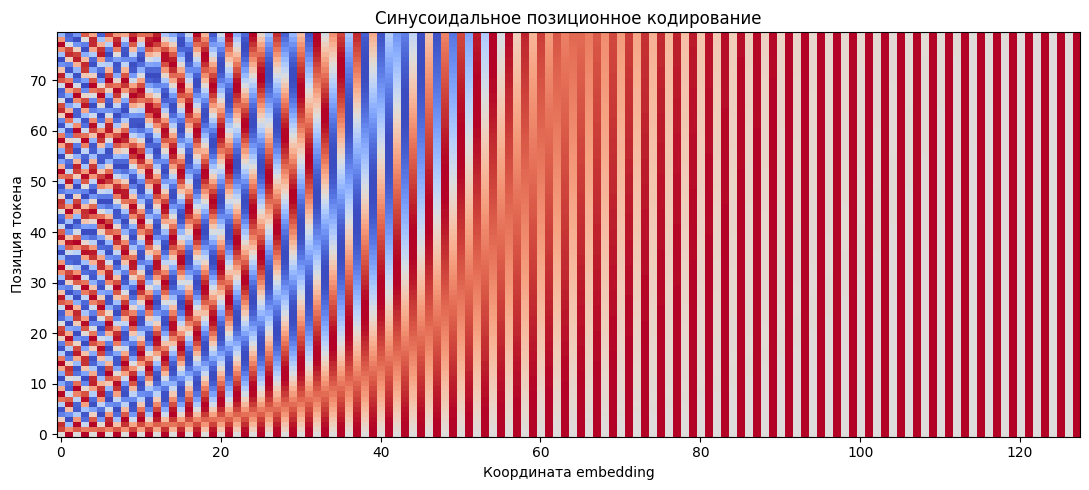

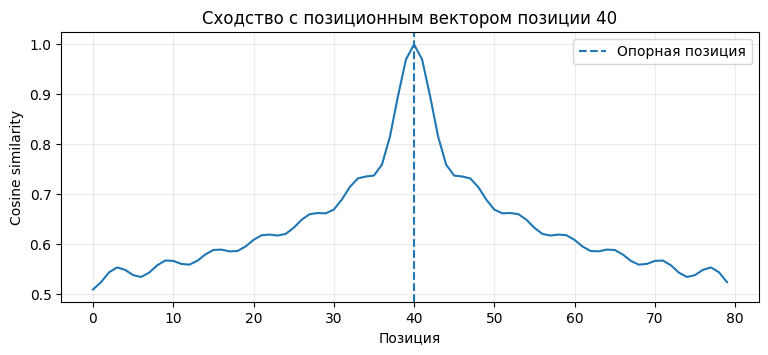

In [9]:
# Проверяем размерности позиционного кодирования и строим его тепловую карту.
import matplotlib.pyplot as plt

positional_demo = PositionalEncoding(embedding_dim=128, max_len=80, dropout=0.0)
demo_x = torch.zeros(2, 40, 128)
demo_pos = positional_demo(demo_x)

print("Вход:", tuple(demo_x.shape))
print("Позиционная матрица:", tuple(positional_demo.pe.shape))
print("Выход:", tuple(demo_pos.shape))

fig, ax = plt.subplots(figsize=(11, 5))
ax.imshow(
    positional_demo.pe[0].numpy(),
    aspect="auto",
    origin="lower",
    cmap="coolwarm",
)
ax.set(
    xlabel="Координата embedding",
    ylabel="Позиция токена",
    title="Синусоидальное позиционное кодирование",
)

plt.tight_layout()
plt.show()

# Вычисляем сходство позиционного вектора с векторами других позиций.
position_vectors = F.normalize(positional_demo.pe[0], dim=-1)
reference_position = 40
similarities = position_vectors @ position_vectors[reference_position]

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(similarities.numpy())
ax.axvline(reference_position, linestyle="--", label="Опорная позиция")
ax.set(
    xlabel="Позиция",
    ylabel="Cosine similarity",
    title=f"Сходство с позиционным вектором позиции {reference_position}",
)
ax.grid(alpha=0.25)
ax.legend()
plt.show()

**Небольшое исследование.** Изучите тепловую карту: какие координаты меняются быстро, а какие - медленно? Посмотрите на график сходства с опорной позицией. Почему по нему можно заметить структуру относительных смещений, но нельзя трактовать позиционный вектор как готовую метку расстояния?

## LayerNorm и residual connections

В Encoder block внимание дополняется нормализацией и остаточными связями. Они помогают стабилизировать обучение и передавать информацию через несколько блоков.

### Layer Normalization

**Layer Normalization (LayerNorm)** нормализует признаки внутри вектора одного токена, а затем применяет обучаемые масштаб и смещение. Для входа формы `[B, T, E]` обычно используют `nn.LayerNorm(E)`.

Для каждого токена вычисляются среднее и дисперсия по последнему измерению $E$ независимо для каждого примера и каждой позиции:


$$
\hat{x}\_i = \frac{x_i-\mu}{\sqrt{\sigma^2+\varepsilon}}, \qquad y_i = \gamma_i\hat{x}_i+\beta_i. 
$$

Здесь $\mu$ и $\sigma^2$ - среднее и дисперсия признаков одного токена, $\varepsilon$ - небольшое число для численной устойчивости, а $\gamma$ и $\beta$ - обучаемые векторы масштаба и смещения длины $E$.

LayerNorm стабилизирует распределение активаций и делает нормализацию независимой от размера мини-батча. Поэтому он особенно удобен в Transformer-архитектурах, где позволяет обрабатывать каждый токен независимо от остальных элементов батча.

In [10]:
# Сравниваем статистики признаков до и после LayerNorm.
layer_norm_demo = nn.LayerNorm(normalized_shape=(128,)).to(device)
norm_input_demo = torch.randn(4, 12, 128, device=device) * 3.0 + 5.0
norm_output_demo = layer_norm_demo(norm_input_demo)

print("Вход: среднее и std по последнему измерению")
print(
    norm_input_demo[0, 0].mean().item(),
    norm_input_demo[0, 0].std(unbiased=False).item(),
)
print("Выход LayerNorm:")
print(
    norm_output_demo[0, 0].mean().item(),
    norm_output_demo[0, 0].std(unbiased=False).item(),
)
print(
    "Обучаемые параметры LayerNorm:",
    sum(p.numel() for p in layer_norm_demo.parameters()),
)

Вход: среднее и std по последнему измерению
4.981873512268066 3.046623706817627
Выход LayerNorm:
-1.1362135410308838e-07 0.9999995231628418
Обучаемые параметры LayerNorm: 256


### Residual connections

Остаточная связь прибавляет вход блока к результату преобразования:

$$
y=x+F(x).
$$

Блоку не обязательно полностью перестраивать представление: он может выучить поправку к уже имеющимся признакам. Прямая ветвь также создаёт короткий путь для распространения градиента через глубокую сеть. В Encoder residual connections используются вокруг self-attention и feed-forward подблока.

## Feed-forward блок Transformer

После self-attention каждый токен проходит через полносвязную сеть, одинаковую для всех позиций:

$$
FFN(x)=W_2\,\sigma(W_1x+b_1)+b_2.
$$

Обычно сначала размерность расширяется, например с `embedding_dim=128` до `hidden_size=256`, а затем возвращается обратно. Self-attention смешивает информацию **между позициями**, а feed-forward блок преобразует признаки **внутри каждой позиции**, независимо от остальных токенов.

## Где хранятся основные знания модели?

Знания распределены по всем обучаемым параметрам: embedding, проекциям Q/K/V, выходным проекциям, feed-forward слоям и другим компонентам. Feed-forward блок часто содержит значительную часть параметров Transformer и хранит множество выученных преобразований признаков.

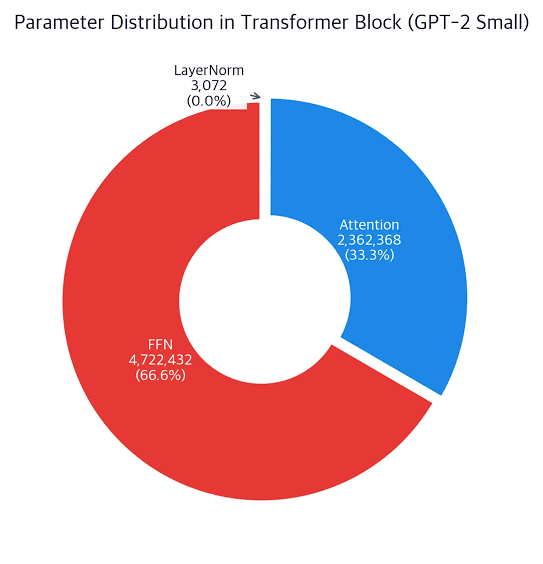

## Структура Transformer encoder

Один Encoder block состоит из multi-head self-attention и feed-forward сети. Вокруг каждого подблока используются residual connection и LayerNorm. Выход блока сохраняет форму `[B, T, E]`: длина последовательности и размерность признаков не меняются.

В этой работе используем вариант **Pre-LayerNorm**: нормализация применяется перед соответствующим подблоком. Схематично вычисления выглядят так:

$$
z=x+\operatorname{MHA}(\operatorname{LayerNorm}(x)),
$$

$$
y=z+\operatorname{FFN}(\operatorname{LayerNorm}(z)).
$$

`nn.TransformerEncoderLayer` реализует один такой блок, а `nn.TransformerEncoder` повторяет его заданное число раз. Параметр `batch_first=True` задаёт формат входа `[B, T, E]`, а `src_key_padding_mask` сообщает слою, какие позиции являются padding.

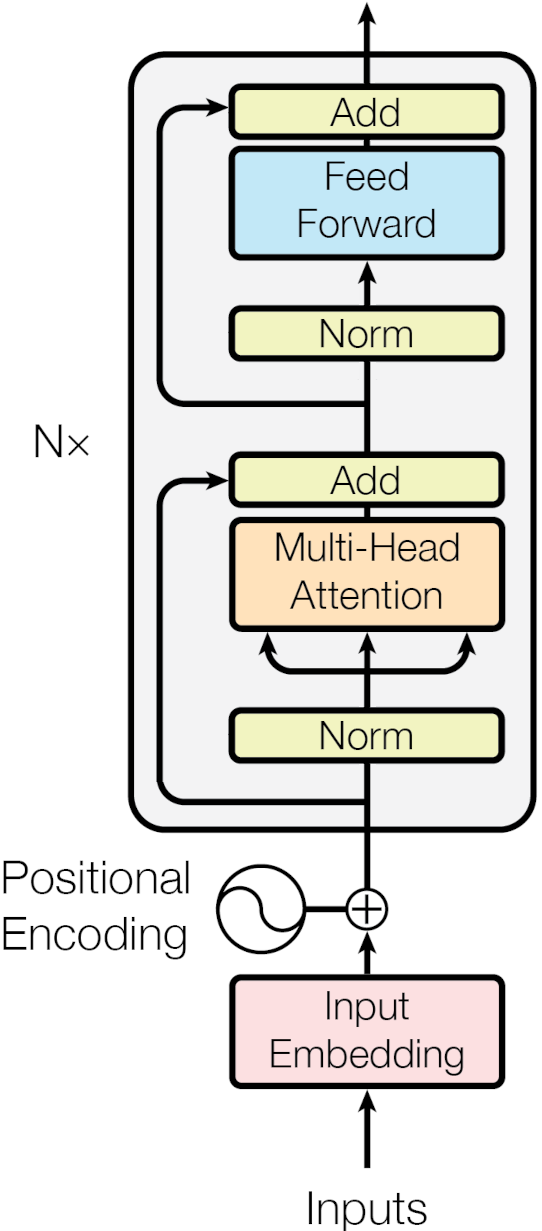

In [11]:
# Создаём небольшой Encoder и проверяем формы входа и выхода.
encoder_layer_demo = nn.TransformerEncoderLayer(
    d_model=128,
    nhead=4,
    dim_feedforward=256,
    dropout=0.2,
    batch_first=True,
    norm_first=True,
).to(device)

encoder_demo = nn.TransformerEncoder(
    encoder_layer_demo, num_layers=2, enable_nested_tensor=False
).to(device)

encoder_input_demo = torch.randn(3, 20, 128, device=device)
encoder_lengths_demo = torch.tensor([20, 17, 12], device=device)
encoder_mask_demo = pad_mask_from_lengths(encoder_lengths_demo)

encoder_output_demo = encoder_demo(
    encoder_input_demo,
    src_key_padding_mask=encoder_mask_demo,
)

print("Вход:", tuple(encoder_input_demo.shape))
print("Padding mask:", tuple(encoder_mask_demo.shape))
print("Выход:", tuple(encoder_output_demo.shape))

Вход: (3, 20, 128)
Padding mask: (3, 20)
Выход: (3, 20, 128)


## Классификация текст с помощью Transformer Encoder

Теперь применим Encoder к задаче классификации текста. Используем тот же датасет, что и в прошлой работе.

In [12]:
# Фиксируем seed и задаём основные гиперпараметры эксперимента в одном месте.
from pathlib import Path
import random
import numpy as np

SEED = 42
BATCH_SIZE = 128
MAX_EPOCHS = 10
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
DATA_DIR = Path("./data")

DATA_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [13]:
# Загружаем AG News и разбиваем на train/validation/test.
from datasets import load_dataset


ds = load_dataset(
    "wangrongsheng/ag_news",
    split="train+test",
    cache_dir=str(DATA_DIR),
)

train_test = ds.train_test_split(
    train_size=50_000,
    test_size=10_000,
    seed=SEED,
    stratify_by_column="label",
)

train_validation = train_test["train"].train_test_split(
    train_size=40_000,
    test_size=10_000,
    seed=SEED,
    stratify_by_column="label",
)

train = train_validation["train"]
validation = train_validation["test"]
test = train_test["test"]

label_feature = train.features["label"]
CLASS_NAMES = (
    label_feature.names
    if hasattr(label_feature, "names")
    else ["World", "Sports", "Business", "Sci/Tech"]
)

In [14]:
# Реализуем простой словарь: частотный отбор, специальные токены, кодирование и декодирование.
from collections import Counter
import re


class Vocabulary:
    """Словарь токенов с поддержкой PAD и UNK."""

    def __init__(self, max_size: int = 30_000, min_freq: int = 2) -> None:
        self.max_size = max_size
        self.min_freq = min_freq

        self.pad_token = "<PAD>"
        self.unk_token = "<UNK>"
        self.stoi = {
            self.pad_token: 0,
            self.unk_token: 1,
        }
        self.itos = [self.pad_token, self.unk_token]

    def tokenize(self, text: str) -> list[str]:
        """Разбивает строку на lowercase-токены из букв и цифр."""
        return re.findall(r"\b\w+\b", text.lower())

    def build(self, texts) -> None:
        """Строит словарь по коллекции текстов."""
        counter = Counter()
        for text in texts:
            counter.update(self.tokenize(text))

        words = [
            (word, frequency)
            for word, frequency in counter.most_common()
            if frequency >= self.min_freq and word not in self.stoi
        ]
        words = words[: self.max_size - len(self.stoi)]

        for word, _ in words:
            self.stoi[word] = len(self.itos)
            self.itos.append(word)

    def encode(self, text: str) -> list[int]:
        """Преобразует текст в индексы; пустой текст кодируется как UNK."""
        tokens = self.tokenize(text)
        if not tokens:
            return [self.unk_idx]
        return [self.stoi.get(token, self.unk_idx) for token in tokens]

    def decode(self, token_ids: list[int]) -> list[str]:
        """Преобразует индексы обратно в токены."""
        return [self.itos[index] for index in token_ids]

    def __len__(self) -> int:
        return len(self.itos)

    @property
    def pad_idx(self) -> int:
        return self.stoi[self.pad_token]

    @property
    def unk_idx(self) -> int:
        return self.stoi[self.unk_token]


# Строим словарь только по обучающим текстам и проверяем несколько преобразований.
MAX_VOCAB_SIZE = 30_000
MIN_FREQ = 2
MAX_LENGTH = 160

vocab = Vocabulary(max_size=MAX_VOCAB_SIZE, min_freq=MIN_FREQ)
vocab.build(train["text"])

In [15]:
# Создаём Dataset, который хранит закодированные последовательности и метки классов.
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence


class EncodedTextDataset(Dataset):
    """Тексты AG News, предварительно преобразованные в последовательности индексов."""

    def __init__(self, split, vocabulary: Vocabulary, max_length: int) -> None:
        self.sequences = []
        self.labels = torch.as_tensor(split["label"], dtype=torch.long)

        for text in split["text"]:
            token_ids = vocabulary.encode(text)[:max_length]
            if not token_ids:
                token_ids = [vocabulary.unk_idx]
            self.sequences.append(torch.tensor(token_ids, dtype=torch.long))

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        return self.sequences[index], self.labels[index]


train_dataset = EncodedTextDataset(train, vocab, MAX_LENGTH)
validation_dataset = EncodedTextDataset(validation, vocab, MAX_LENGTH)
test_dataset = EncodedTextDataset(test, vocab, MAX_LENGTH)


# Объединяем последовательности разной длины в батч и сохраняем их настоящие длины.
def collate_padded(batch: list[TensorPair]) -> tuple[TensorPair, torch.Tensor]:
    sequences, labels = zip(*batch)
    lengths = torch.tensor(
        [sequence.numel() for sequence in sequences], dtype=torch.long
    )

    tokens = pad_sequence(
        sequences,
        batch_first=True,
        padding_value=vocab.pad_idx,
    )
    labels = torch.stack(labels).long()

    return (tokens, lengths), labels


# Создаём DataLoader.
train_sequence_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    num_workers=0,
    collate_fn=collate_padded,
    pin_memory=torch.cuda.is_available(),
)
validation_sequence_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_padded,
    pin_memory=torch.cuda.is_available(),
)
test_sequence_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_padded,
    pin_memory=torch.cuda.is_available(),
)

## Токен **`[CLS]`** и классификация всей последовательности

Encoder возвращает контекстное представление для каждой позиции входной последовательности. При этом для классификации всего текста нужен один вектор, который будет представлять последовательность целиком.

Для этого в начало последовательности добавляется специальный обучаемый токен `[CLS]` (*Classification Token*). Он не соответствует ни одному слову исходного текста и не содержит заранее заданной информации. Вместо этого модель обучается использовать его как обобщённое представление всей последовательности.

В процессе работы Transformer токен `[CLS]` участвует в self-attention наравне с остальными токенами. Благодаря этому он может учитывать информацию из всех позиций входной последовательности. После прохождения через Encoder его контекстное представление используется как векторное представление всего текста.

В модели `cls_token` задаётся как обучаемый параметр `nn.Parameter` формы `[1, 1, E]`. Первая размерность соответствует размеру батча, вторая - длине последовательности, третья - размерности вектора.

Перед объединением с embedding токенов этот параметр расширяется до размера батча `[B, 1, E]` с помощью `expand`.

Операция `expand` не создаёт отдельную копию параметра для каждого элемента батча, а позволяет использовать один и тот же обучаемый вектор для всех последовательностей.

Затем `[CLS]` конкатенируется с остальными токенами по измерению последовательности (`dim=1`). В результате длина каждой последовательности увеличивается на один токен, а итоговая форма становится `[B, T+1, E]`.

Поскольку `[CLS]` занимает позицию `0`, позиционное кодирование также должно учитывать дополнительную позицию. Поэтому вместо длины `MAX_LENGTH` используется `MAX_LENGTH + 1`. Это позволяет каждому токену, включая `[CLS]`, получить соответствующее позиционное представление.

Токен `[CLS]` не является padding: это полноценный элемент последовательности, который должен участвовать в self-attention. Поэтому при добавлении его в начало последовательности к padding mask необходимо добавить один столбец `False` слева. В результате маска приобретает форму `[B, T+1]` и сохраняет соответствие между позициями токенов и элементами маски.

### Реализация TransformerTextClassifier

Соединим компоненты в одной модели:

- `nn.Embedding` преобразует индексы токенов в векторы;
- обучаемый `[CLS]` добавляется в начало последовательности;
- `PositionalEncoding` добавляет информацию о позиции;
- `nn.TransformerEncoder` строит контекстные представления с учётом padding mask;
- выход на позиции `[CLS]` передаётся dropout и линейному классификатору.

In [ ]:
# Реализуем классификатор текста на основе Transformer encoder.
class TransformerTextClassifier(nn.Module):
    """Классификатор AG News на основе Transformer encoder."""

    def __init__(
        self,
        vocab_size: int,
        num_classes: int,
        pad_idx: int,
        embedding_dim: int = 128,
        hidden_size: int = 256,
        num_heads: int = 4,
        num_layers: int = 2,
        max_len: int = MAX_LENGTH,
        dropout: float = 0.2,
    ) -> None:
        super().__init__()
        self.embedding_dim = embedding_dim
        self.hidden_size = hidden_size
        self.num_layers = num_layers

        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)

        # Обучаемый вектор [CLS] размером (1, 1, embedding_dim).
        self.cls_token = nn.Parameter(torch.randn(1, 1, embedding_dim) * 0.02)

        self.positional_encoder = PositionalEncoding(
            embedding_dim=embedding_dim,
            max_len=max_len + 1,
            dropout=dropout,
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embedding_dim,
            nhead=num_heads,
            dim_feedforward=hidden_size,
            dropout=dropout,
            batch_first=True,
            norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(
            encoder_layer, num_layers=num_layers, enable_nested_tensor=False
        )

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(embedding_dim, num_classes)

    def forward(self, tokens: torch.Tensor, lengths: torch.Tensor) -> torch.Tensor:
        batch_size = tokens.size(0)

        # Строим padding mask.
        pad_mask = pad_mask_from_lengths(lengths.to(tokens.device))

        # Преобразуем индексы токенов в embedding и масштабируем их.
        embedded = self.embedding(tokens) * math.sqrt(self.embedding_dim)

        # Расширяем [CLS] на весь батч и добавляем его в начало последовательности.
        cls_tokens = self.cls_token.expand(batch_size, -1, -1) * math.sqrt(
            self.embedding_dim
        )
        embedded = torch.cat((cls_tokens, embedded), dim=1)

        # Для [CLS] добавляем False: эта позиция не является padding.
        cls_mask = torch.zeros((batch_size, 1), dtype=torch.bool, device=tokens.device)
        pad_mask = torch.cat((cls_mask, pad_mask), dim=1)

        # Добавляем позиционную информацию и обрабатываем последовательность Encoder.
        encoded = self.positional_encoder(embedded)
        encoded = self.encoder(encoded, src_key_padding_mask=pad_mask)

        # Используем контекстное представление позиции [CLS] для классификации текста.
        cls_out = encoded[:, 0, :]
        return self.classifier(self.dropout(cls_out))

In [17]:
# Проверяем классификатор на одном реальном батче до обучения.
(sequence_tokens, sequence_lengths), sequence_labels = next(iter(train_sequence_loader))

transformer_demo = TransformerTextClassifier(
    vocab_size=len(vocab),
    num_classes=len(CLASS_NAMES),
    pad_idx=vocab.pad_idx,
).to(device)

with torch.inference_mode():
    demo_transformer_logits = transformer_demo(
        sequence_tokens.to(device),
        sequence_lengths,
    )

transformer_parameter_count = sum(
    parameter.numel()
    for parameter in transformer_demo.parameters()
    if parameter.requires_grad
)

print("Входные токены:", tuple(sequence_tokens.shape))
print("Длины:", tuple(sequence_lengths.shape))
print("Логиты:", tuple(demo_transformer_logits.shape))
print("Число обучаемых параметров:", f"{transformer_parameter_count:,}")

Входные токены: (128, 89)
Длины: (128,)
Логиты: (128, 4)
Число обучаемых параметров: 3,936,772


## Обучение Transformer

Для обучения используем ту же инфраструктуру `TextClassifierLitModel`, что и в лабораторной работе № 5. Она получает батч с входными тензорами и метками, вызывает модель и рассчитывает `CrossEntropyLoss`. 

In [ ]:
%pip install lightning -qU

In [19]:
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..")))

In [20]:
# Переопределим _shared_step и forward.
from templates.lit import LitModel


class TextClassifierLitModel(LitModel):
    def _shared_step(
        self, batch: tuple[list[torch.Tensor], torch.Tensor]
    ) -> torch.Tensor:
        """Выполняет общий прямой проход и вычисляет loss"""

        inputs, labels = batch
        logits = self(*inputs)
        loss = self.criterion(logits, labels)
        accuracy = (logits.argmax(dim=1) == labels).float().mean()

        return loss, accuracy

    def forward(self, *args: torch.Tensor) -> torch.Tensor:
        """Возвращает логиты модели для входного батча."""
        return self.model(*args)

In [ ]:
# Обучаем модель.
transformer_lit = TextClassifierLitModel(
    model=TransformerTextClassifier,
    vocab_size=len(vocab),
    num_classes=len(CLASS_NAMES),
    pad_idx=vocab.pad_idx,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    seed=SEED,
)

transformer_metrics = transformer_lit.fit(
    train_loader=train_sequence_loader,
    validation_loader=validation_sequence_loader,
    epochs=MAX_EPOCHS,
    patience=MAX_EPOCHS,
)

transformer_best_model = transformer_lit.to(device).model.eval()

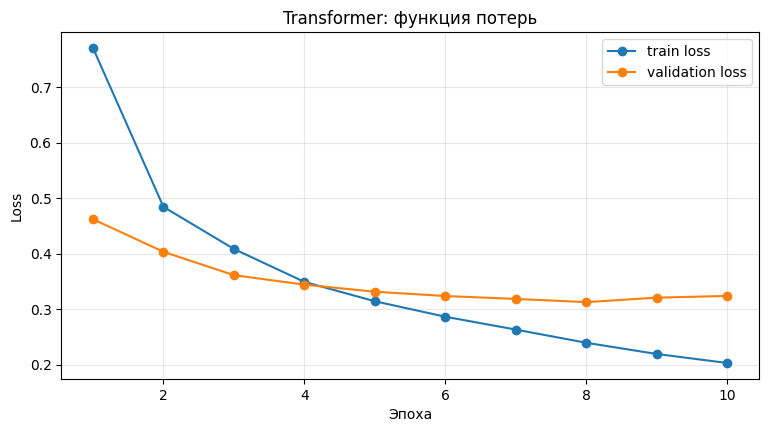

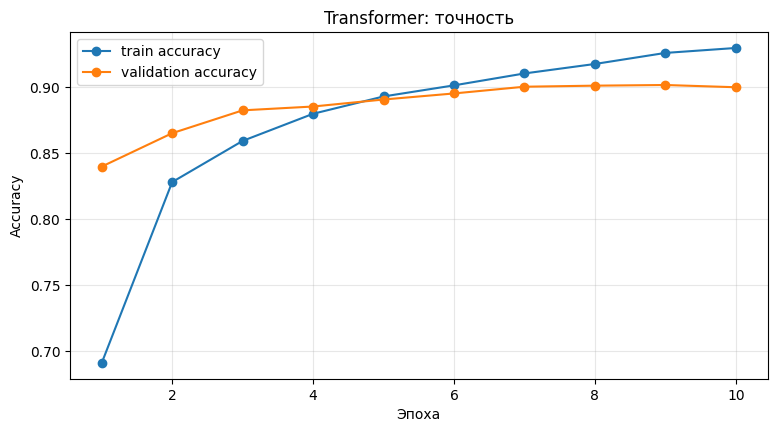

In [22]:
# Строим графики истории эксперимента.
history = transformer_metrics.groupby("epoch")[
    ["train_loss", "train_accuracy", "val_loss", "val_accuracy"]
].last()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(history.index + 1, history["train_loss"], marker="o", label="train loss")
ax.plot(history.index + 1, history["val_loss"], marker="o", label="validation loss")
ax.set(xlabel="Эпоха", ylabel="Loss", title=f"Transformer: функция потерь")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(
    history.index + 1, history["train_accuracy"], marker="o", label="train accuracy"
)
ax.plot(
    history.index + 1,
    history["val_accuracy"],
    marker="o",
    label="validation accuracy",
)
ax.set(xlabel="Эпоха", ylabel="Accuracy", title=f"Transformer: точность")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

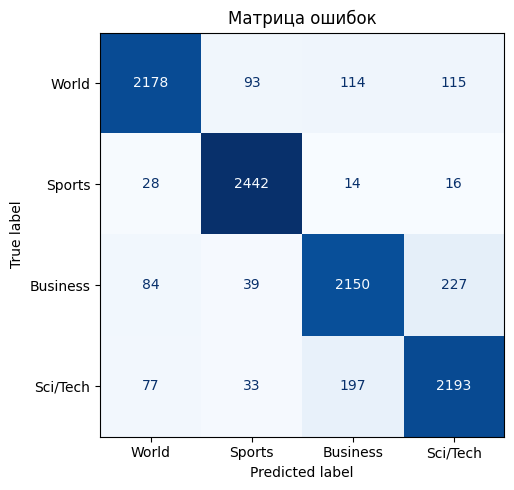

In [23]:
# Получаем предсказанные классы и истинные метки для всей тестовой выборки.
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix


@torch.inference_mode()
def collect_predictions(
    model: nn.Module,
    loader: DataLoader,
    target_device: torch.device,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Возвращает истинные метки, предсказания и вероятности классов."""
    model.eval()

    all_targets: list[np.ndarray] = []
    all_predictions: list[np.ndarray] = []
    all_probabilities: list[np.ndarray] = []

    for data, labels in loader:
        # Переносим признаки на то же устройство, где расположена модель.
        if isinstance(data, (list, tuple)):
            data = [item.to(target_device) for item in data]
        else:
            data = data.to(target_device)

        # Модель возвращает логиты; Softmax преобразует их в вероятности для анализа.
        logits = model(*data)
        probabilities = torch.softmax(logits, dim=1)
        predictions = logits.argmax(dim=1)

        all_targets.append(labels.cpu().numpy())
        all_predictions.append(predictions.cpu().numpy())
        all_probabilities.append(probabilities.cpu().numpy())

    return (
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        np.concatenate(all_probabilities),
    )


y_true, y_pred, _ = collect_predictions(
    transformer_best_model, test_sequence_loader, device
)

confusion = confusion_matrix(y_true, y_pred, labels=list(range(4)))

fig, ax = plt.subplots(figsize=(5.25, 5))
confusion_display = ConfusionMatrixDisplay(
    confusion_matrix=confusion,
    display_labels=CLASS_NAMES,
)
confusion_display.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Матрица ошибок")
plt.tight_layout()
plt.show()

**Небольшое исследование.** Сравните качество предсказаний с моделями из работы № 5. Лучше ли transformer encoder рассмотренных ранее архитектур?

## Специфика обучения трансформеров 

Трансформеры способны эффективно выявлять сложные зависимости в тексте и учитывать контекст слов, однако для их эффективного обучения, как правило, требуется значительно больше данных и вычислительных ресурсов. В лабораторной работе № 5 для обучения RNN количество данных датасета AG News было ограничено 40 000 примерами. Поэтому результаты сравнения не являются полностью объективными: при увеличении обучающей выборки Transformer Encoder потенциально может показать более высокую точность. Однако на ограниченном объёме данных он не обязательно превосходит рекуррентные архитектуры.

### Визуализация attention weights

`nn.TransformerEncoderLayer` использует `nn.MultiheadAttention` внутри. В обычном прямом проходе Encoder веса внимания не возвращаются наружу, поэтому для их извлечения воспользуемся хуками.

Зарегистрируем `forward_pre_hook` и `forward_hook` на `self_attn` каждого Encoder block. Первый хук изменяет аргументы вызова attention, устанавливая `need_weights=True` и `average_attn_weights=False`. Благодаря этому attention-модуль возвращает матрицы внимания отдельно для каждой головы.

Второй хук извлекает полученные attention weights из результата работы модуля и сохраняет их в отдельный список.

После регистрации хуков выполним обычный прямой проход через Encoder. Таким образом, каждый Encoder block получит корректные входные представления, сформированные предыдущим блоком, а attention weights будут автоматически собраны хуками.

После завершения прямого прохода удалим все зарегистрированные хуки, чтобы они не влияли на последующие вызовы модели.

Для одного текста ожидаем форму весов каждого слоя `[1, H, T+1, T+1]`, где `H` - количество голов внимания, а дополнительная позиция соответствует `[CLS]`.

Таким образом, получим отдельные матрицы внимания для каждой головы каждого Encoder block и сможем сравнить, как меняется распределение внимания между слоями модели.

In [49]:
# Функция извлечения attention weights через хуки.
from typing import Any


@torch.inference_mode()
def get_all_layers_attention(
    model: TransformerTextClassifier,
    tokens: torch.Tensor,
    lengths: torch.Tensor,
) -> list[torch.Tensor]:
    model.eval()
    tokens = tokens.to(device)
    lengths = lengths.to(device)

    all_weights: list[torch.Tensor] = []
    hooks: list[torch.utils.hooks.RemovableHandle] = []

    # Изменяем аргументы вызова attention, чтобы получить веса для каждой головы.
    def attention_pre_hook(
        module: torch.nn.Module,
        args: tuple[Any, ...],
        kwargs: dict[str, Any],
    ) -> tuple[tuple[Any, ...], dict[str, Any]]:
        kwargs["need_weights"] = True
        kwargs["average_attn_weights"] = False
        return args, kwargs

    # Извлекаем attention weights из результата работы attention-модуля.
    def attention_hook(
        module: torch.nn.Module,
        inputs: tuple[Any, ...],
        output: tuple[torch.Tensor, torch.Tensor | None],
    ) -> None:
        weights = output[1]
        if weights is not None:
            all_weights.append(weights.detach())

    # Регистрируем хуки на self-attention каждого Encoder block.
    for layer in model.encoder.layers:
        hooks.append(
            layer.self_attn.register_forward_pre_hook(
                attention_pre_hook,
                with_kwargs=True,
            )
        )
        hooks.append(layer.self_attn.register_forward_hook(attention_hook))

    try:
        # Последовательно пропускаем представления через все Encoder blocks.
        model(tokens, lengths)
    finally:
        # Удаляем зарегистрированные хуки после выполнения прямого прохода.
        for hook in hooks:
            hook.remove()

    return all_weights

In [50]:
# Выбираем короткую новость, чтобы подписи токенов оставались читаемыми.
attention_index = next(
    index
    for index, (sequence, _) in enumerate(test_dataset)
    if 5 <= sequence.numel() <= 24
)

attention_sequence, attention_label = test_dataset[attention_index]
(attention_tokens, attention_lengths), _ = collate_padded(
    [(attention_sequence, attention_label)]
)

# Извлекаем attention weights из всех Encoder blocks выбранной модели.
all_layer_weights = get_all_layers_attention(
    transformer_best_model,
    attention_tokens,
    attention_lengths,
)

attention_tokens_list = ["[CLS]"] + vocab.decode(attention_sequence.tolist())

with torch.inference_mode():
    attention_logits = transformer_best_model(
        attention_tokens.to(device),
        attention_lengths.to(device),
    )

print("Текст:", test[attention_index]["text"])
print("Истинный класс:", CLASS_NAMES[int(attention_label)])
print("Предсказанный класс:", CLASS_NAMES[int(attention_logits.argmax(dim=1).item())])
print("Количество слоёв:", len(all_layer_weights))
print("Ожидаемое количество слоёв:", transformer_best_model.encoder.num_layers)

for layer_index, weights in enumerate(all_layer_weights):
    print(f"Слой {layer_index + 1}: {tuple(weights.shape)}")

Текст: Peres calls for early general election The leader of the opposition Labour party in Israel, Shimon Peres, has called for an early general election. 
Истинный класс: World
Предсказанный класс: World
Количество слоёв: 2
Ожидаемое количество слоёв: 2
Слой 1: (1, 4, 25, 25)
Слой 2: (1, 4, 25, 25)


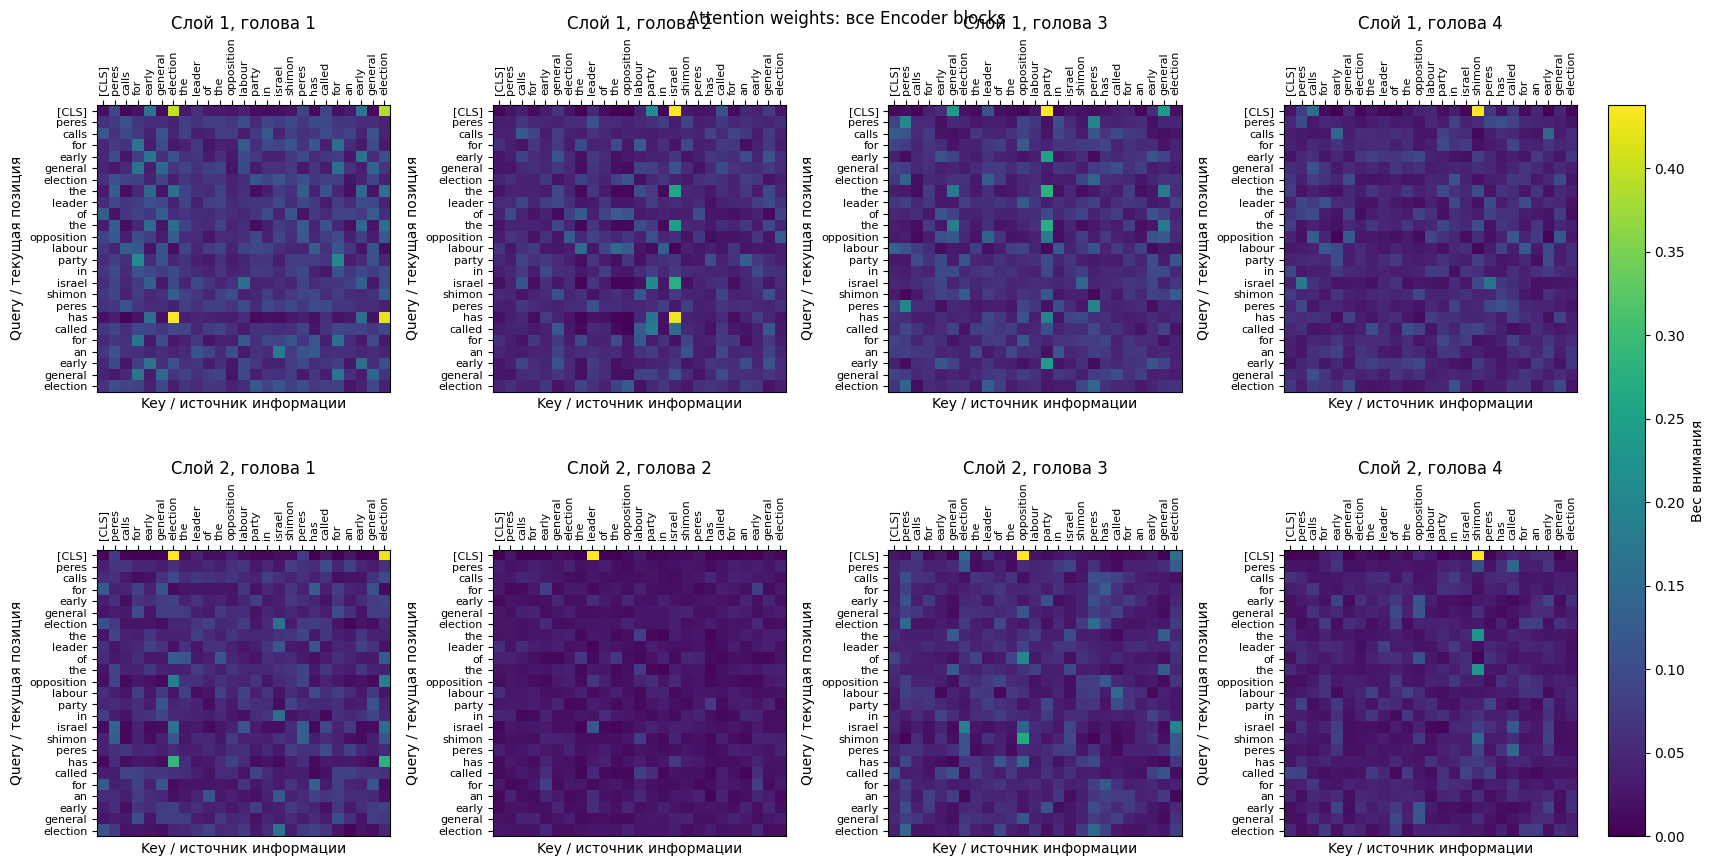

In [51]:
# Визуализируем матрицы внимания отдельно для каждой головы каждого Encoder block.
num_layers = len(all_layer_weights)
num_heads_to_plot = all_layer_weights[0].size(1)

fig, axes = plt.subplots(
    num_layers,
    num_heads_to_plot,
    figsize=(5 * num_heads_to_plot, 4.75 * num_layers),
    squeeze=False,
    gridspec_kw={"wspace": 0.35, "hspace": 0.55},
)

for layer_index, layer_weights in enumerate(all_layer_weights):
    attention_weights_one = layer_weights[0].cpu()

    for head_index, ax in enumerate(axes[layer_index]):
        image = ax.imshow(
            attention_weights_one[head_index].numpy(),
            aspect="auto",
            vmin=0.0,
            cmap="viridis",
        )

        ax.set_title(f"Слой {layer_index + 1}, голова {head_index + 1}")

        ax.set_xticks(range(len(attention_tokens_list)))
        ax.set_yticks(range(len(attention_tokens_list)))
        ax.set_xticklabels(attention_tokens_list, rotation=90, fontsize=8)
        ax.set_yticklabels(attention_tokens_list, fontsize=8)
        ax.tick_params(top=True, labeltop=True, bottom=False, labelbottom=False)

        ax.set_xlabel("Key / источник информации")
        ax.set_ylabel("Query / текущая позиция")

cbar = fig.colorbar(
    image,
    ax=axes.ravel().tolist(),
    location="right",
    fraction=0.025,
    pad=0.02,
)
cbar.set_label("Вес внимания")

fig.suptitle("Attention weights: все Encoder blocks")

plt.show()

**Небольшое исследование.** Посмотрите, какие токены получают больший вес из позиции `[CLS]`. Отличаются ли распределения у разных голов? Можно ли заметить похожие закономерности? 

## Контрольные вопросы

- В чём состоит идея механизма self-attention?
- Какую роль выполняют Query, Key и Value?
- Почему в scaled dot-product attention используется деление на $\sqrt{d_k}$?
- Как интерпретировать строку матрицы attention weights?
- Зачем нужны несколько голов внимания?
- Почему после конкатенации голов используется дополнительная линейная проекция?
- Как объединение матриц Q, K и V помогает эффективнее выполнять вычисления?
- Почему self-attention без позиционной информации не учитывает порядок токенов?
- Как устроено синусоидальное позиционное кодирование?
- Зачем нужна LayerNorm и чем она отличается от BatchNorm?
- Какую роль выполняют residual connections?
- Для чего нужен токен `[CLS]` и почему его позиция не должна маскироваться?
- Какую информацию содержит `src_key_padding_mask`?
- Почему небольшой Transformer, обучаемый с нуля на ограниченном наборе данных, не обязательно превосходит рекуррентную модель?